In [18]:
import pandas as pd
from pandas import read_csv
from matplotlib import pyplot 
from sklearn.model_selection import train_test_split 
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

In [19]:
path="C:\\Users\\india\\OneDrive\\Desktop\\data science\\iris.csv"
names=['sepal-length','sepal-width','petal-length','petal-width','class']
dataset=read_csv(path,names=names)
print(dataset)
#split the dataset into training and testing
array=dataset.values
X=array[:,0:4]
Y=array[:,4]
#we are creating a training and validation set--->using--- train_test_split()
#test_size=0.20--->20% percent of data will be used as a test data
#random state=1
#shuffle---> shuffling the data
X_train, X_validation,Y_train, Y_validation=train_test_split(X,Y,test_size=0.20,random_state=1,shuffle=True)

     sepal-length  sepal-width  petal-length  petal-width           class
0             5.1          3.5           1.4          0.2     Iris-setosa
1             4.9          3.0           1.4          0.2     Iris-setosa
2             4.7          3.2           1.3          0.2     Iris-setosa
3             4.6          3.1           1.5          0.2     Iris-setosa
4             5.0          3.6           1.4          0.2     Iris-setosa
..            ...          ...           ...          ...             ...
145           6.7          3.0           5.2          2.3  Iris-virginica
146           6.3          2.5           5.0          1.9  Iris-virginica
147           6.5          3.0           5.2          2.0  Iris-virginica
148           6.2          3.4           5.4          2.3  Iris-virginica
149           5.9          3.0           5.1          1.8  Iris-virginica

[150 rows x 5 columns]


[('LR', LogisticRegression()), ('KNN', KNeighborsClassifier())]


C:\Users\india\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LR:0.966667(0.040825)
KNN:0.958333(0.041667)


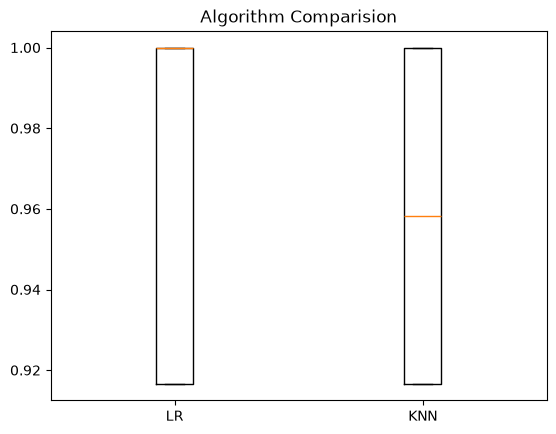

In [44]:
# empty list for the models
models=[]
#models.append(('LR',LogisticRegression(solver='liblinear',multi_class='ovr')))
models.append(("LR",LogisticRegression()))
models.append(('KNN',KNeighborsClassifier()))
print(models)
result=[]
names=[]
for name,model in models:
    kfold=StratifiedKFold(n_splits=10,random_state=1,shuffle=True)
    cv_results=cross_val_score(model,X_train,Y_train,cv=kfold,scoring='accuracy')
    result.append(cv_results)
    names.append(name)
    print('%s:%f(%f)'%(name,cv_results.mean(),cv_results.std()))
#compare the algo
pyplot.boxplot(result,tick_labels=names)
pyplot.title('Algorithm Comparision')
pyplot.show()

In [61]:
import math
x = [10, 20, 30, 40, 50, 60]
y = [30, 12, 34, 32, 65, 50]
# test point
tx = 34
ty = 20
k = 2
distance = []
for i in range(len(x)):
    d = math.sqrt(pow((x[i] - tx),2)+ pow((y[i] - ty),2))
    distance.append(d)
    print(x[i], y[i], "=", d)

distance.sort()
print("Nearest 2 points:")
print(distance[:k])

10 30 = 26.0
20 12 = 16.1245154965971
30 34 = 14.560219778561036
40 32 = 13.416407864998739
50 65 = 47.75981574503821
60 50 = 39.698866482558415
Nearest 2 points:
[13.416407864998739, 14.560219778561036]
